In [1]:
import time
import tracemalloc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Load Data
df = pd.read_csv('../data/komdigi_hoaks.csv') 
df['teks'] = df['title'].fillna('') + ' ' + df['excerpt'].fillna('')
df = df[df['teks'].str.strip() != ''].reset_index(drop=True)

y = df['topics'] # <-- Pastikan ini bener

# TF-IDF & Split
tfidf = TfidfVectorizer(max_features=1000)
X = tfidf.fit_transform(df['teks'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [2]:
NAMA_PENGUJIAN = "KNN - EUCLIDEAN"
METRIK = 'euclidean' 

model = KNeighborsClassifier(n_neighbors=5, metric=METRIK)

# Mulai hitung waktu & memori
tracemalloc.start()
waktu_mulai = time.time()

# Training & Predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

waktu_selesai = time.time()
mem_sekarang, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

hasil_waktu = waktu_selesai - waktu_mulai
hasil_memori_mb = mem_puncak / (1024 * 1024)

In [3]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=" * 50)
print(f"HASIL PENGUJIAN: {NAMA_PENGUJIAN}")
print("=" * 50)
print(f"1. Akurasi          : {acc:.4f}")
print(f"2. Precision        : {prec:.4f}")
print(f"3. Recall           : {rec:.4f}")
print(f"4. F1-Score         : {f1:.4f}")
print(f"5. Waktu Eksekusi   : {hasil_waktu:.4f} detik")
print(f"6. Penggunaan Memori: {hasil_memori_mb:.2f} MB")
print("=" * 50)

HASIL PENGUJIAN: KNN - EUCLIDEAN
1. Akurasi          : 0.8349
2. Precision        : 0.7867
3. Recall           : 0.8349
4. F1-Score         : 0.8043
5. Waktu Eksekusi   : 0.3230 detik
6. Penggunaan Memori: 53.81 MB


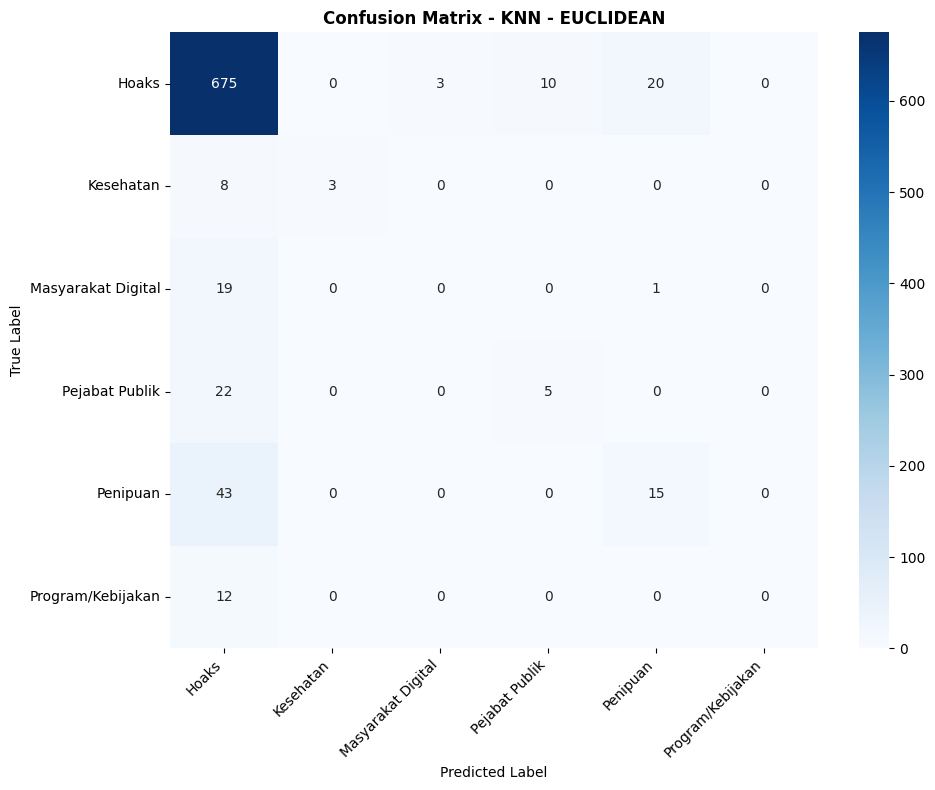

In [4]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
labels = np.unique(np.concatenate((y_test, y_pred)))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix - {NAMA_PENGUJIAN}', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()